# V19: accessible paired-classifier mirror

**INTERIM source and offline asset results. Quality and GPU runtime are unmeasured.**
Retain official 0.82987 / rank 23; the rank ≤19 goal remains active. This notebook
records the pinned mirror, verified head, input semantics, native matrix-layout
correction and available asset receipts. It does not estimate a competition score.

Candidate: [wath5/kgl_lmsys_pref_classif](https://huggingface.co/wath5/kgl_lmsys_pref_classif),
revision `cd24909db06583ecf00e65b6919c6cc1531c9885`. Original author-run lineage
is unverified; a card attribution or finite head does not authenticate training.
The fixed recipe and gates are in [protocol](../docs/SPAN_019_ASSET_PROTOCOL.md),
with [source results](../docs/SPAN_019_SOURCE_RESULTS.md).

Pinned source: wath5/kgl_lmsys_pref_classif cd24909db06583ecf00e65b6919c6cc1531c9885
Tensor keys: 1347 ; finite classifier shape: [3, 3584]
Config pad: 1 ; effective native pad: 0
EOS: 1 ; padding: left ; max input tokens: 2001


,tokens,padded_tokens,offset,pool_index,identical
0,29,2000,1971,28,True
1,32,2000,1968,31,True
2,35,2000,1965,34,True
3,35,2000,1965,34,True
4,2001,2001,0,2000,True
5,2001,2001,0,2000,True
6,2001,2001,0,2000,True
7,2001,2001,0,16,True


,seed,max_abs,weight_stride,passed
0,42,0.0,"[1, 128]",True
1,43,0.0,"[1, 128]",True
2,44,0.0,"[1, 128]",True


Preserved first failure: ordinary-layout synthetic projection max difference 0.015625
Weights were bit-identical: True
Correct native-layout synthetic projections match exactly; whole-model GPU probabilities unmeasured.


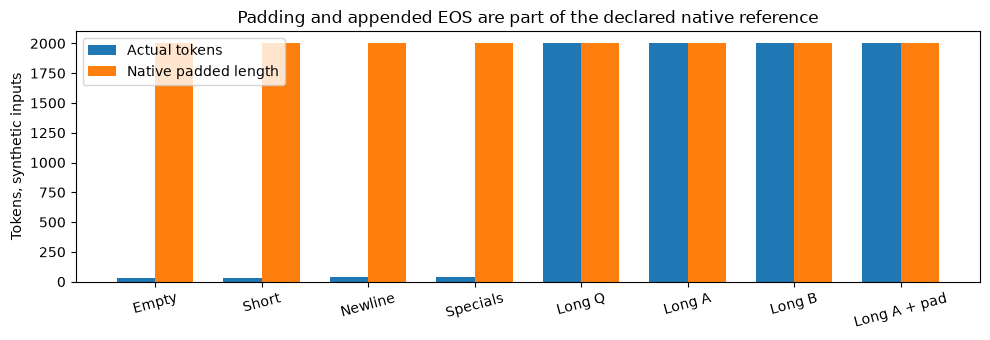

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
REPO=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
PUB=REPO/'results/span_019'
def read(name): return json.loads((PUB/name).read_text())
s=read('source_observation.json');c=read('native_cpu_controls.json');failure=read('native_cpu_attempt_1.json')
print('Pinned source:',s['repository'],s['revision'])
print('Tensor keys:',s['tensor_keys'],'; finite classifier shape:',s['classifier_head_shape'])
print('Config pad:',s['pad_token_id'],'; effective native pad:',c['effective_native_pad_token_id'])
print('EOS:',c['eos_token_id'],'; padding:',c['padding_side'],'; max input tokens:',c['maximum_input_tokens'])
display(pd.DataFrame(c['synthetic_input_checks']))
display(pd.DataFrame(c['synthetic_native_GPTQ_arithmetic']))
print('Preserved first failure: ordinary-layout synthetic projection max difference',failure['linear_max_abs'])
print('Weights were bit-identical:',failure['max_abs_weight']==0)
print('Correct native-layout synthetic projections match exactly; whole-model GPU probabilities unmeasured.')
fixtures=['Empty','Short','Newline','Specials','Long Q','Long A','Long B','Long A + pad']
rows=c['synthetic_input_checks'];x=list(range(len(rows)))
fig,ax=plt.subplots(figsize=(10,3.5))
ax.bar([i-.18 for i in x],[r['tokens'] for r in rows],.36,label='Actual tokens')
ax.bar([i+.18 for i in x],[r['padded_tokens'] for r in rows],.36,label='Native padded length')
ax.set_xticks(x,fixtures,rotation=15);ax.set_ylabel('Tokens, synthetic inputs');ax.legend()
ax.set_title('Padding and appended EOS are part of the declared native reference')
fig.tight_layout();plt.show()
assert c['passed'] and not c['real_model_logits_compared'] and not s['quality_measured']

In [2]:
selection=read('evaluation_selection.json')
print('Fixed evaluation counts:',{k:len(selection[k]) for k in ['control_ids','uniform_ids','long_ids','later_ids']})
print('Targets used for selection:',selection['uses_targets_for_selection'])
print('Original votes overlap checkpoint training; later cohort previously inspected and differs in domain.')
if (PUB/'token_reference.json').exists():
 tokens=read('token_reference.json')
 display(pd.DataFrame([{'cohort':name,**r} for name,r in tokens['cohorts'].items()])[
  ['cohort','rows','mean_tokens','max_tokens','seconds']])
 print('Token/absolute-position/pool fingerprints fixed before GPU inference; no winner labels read.')
if (PUB/'worker_cpu_validation.json').exists():
 checks=read('worker_cpu_validation.json')
 print('Tiny saved-model tests:',checks['native_test_count'],'; pipeline tests:',checks['pipeline_test_count'])
 print('CPU runtime:',checks['runtime'])
 print('Selected production backend:',checks['production_backend'])
 print('Real GPU fit/speed verified:',checks['production_backend_memory_speed_verified'])
for filename in ['weight_acquisition.json','dense_expansion.json']:
 if (PUB/filename).exists():
  r=read(filename)
  print(filename,{k:r[k] for k in ['complete','total_weight_file_bytes','tensor_keys','total_tensor_bytes',
    'head_bytes_identical','runtime_native_layout_required','new_gpu_executions','quality_measured','gpu_admitted'] if k in r})
 else: print(filename,'not complete at this notebook snapshot')
print('No training or new quantization. Offline source/asset checks do not admit a GPU or official submission.')
print('Native whole-model controls, fixed quality comparison, actual512/fullwarmup runtime and official trial remain pending.')

Fixed evaluation counts: {'control_ids': 256, 'uniform_ids': 512, 'long_ids': 64, 'later_ids': 1024}
Targets used for selection: False
Original votes overlap checkpoint training; later cohort previously inspected and differs in domain.


,cohort,rows,mean_tokens,max_tokens,seconds
0,control,256,649.351562,2001,0.406586
1,uniform,512,662.142578,2001,0.545132
2,long,64,2001.000000,2001,0.945073
3,test,3,748.666667,1712,0.004374
4,warmup,80,575.837500,2001,0.036385
5,reference,12,555.833333,2001,0.014050
6,source,1024,685.230469,2001,1.114300


Token/absolute-position/pool fingerprints fixed before GPU inference; no winner labels read.
Tiny saved-model tests: 3 ; pipeline tests: 2
CPU runtime: {'python': '3.11.15', 'numpy': '1.26.4', 'torch': '2.15.0+cpu', 'transformers': '4.42.3'}
Selected production backend: two native GPTQ8 replicas on separate T4s; full native eager decoder
Real GPU fit/speed verified: False
weight_acquisition.json {'complete': True, 'total_weight_file_bytes': 10361181040, 'new_gpu_executions': 0, 'quality_measured': False}
dense_expansion.json not complete at this notebook snapshot
No training or new quantization. Offline source/asset checks do not admit a GPU or official submission.
Native whole-model controls, fixed quality comparison, actual512/fullwarmup runtime and official trial remain pending.


In [3]:
for name in ['asset_upload.json','upload_live_observation.json']:
 if (PUB/name).exists():
  r=read(name)
  print(name,{k:r[k] for k in ['at','dataset','ready','status','process_exists','last_observed_open_file',
    'last_observed_file_read_position_bytes','file_total_bytes','service_ready_unproven'] if k in r})
if (PUB/'quality_preparation.json').exists():
 q=read('quality_preparation.json')
 display(pd.DataFrame([{'cohort':name,'total_rows':r['rows'],'routed_rows':r['selected_rows'],
  'routed_work_fraction':r['work_fraction']} for name,r in q['routes'].items()]))
 print('Comparator routes frozen from verified old predictions; winner labels used:',q['uses_winner_labels'])
if (PUB/'classifier_followup_cell_rehearsals.json').exists():
 r=read('classifier_followup_cell_rehearsals.json')
 print('Followup notebook local checks passed:',r['passed'])
 print('These are CPU orchestration checks; real model GPU exercised:',r['real_model_gpu_exercised'])
print('The separate followup is conditional on the initial engineering/runtime gate; no new score is available.')

asset_upload.json {'at': '2026-11-08T11:24:43.459748+00:00', 'dataset': 'arseniytrushin/llm-span019-native-classifier/1', 'ready': True, 'status': 'ready'}
upload_live_observation.json {'at': '2026-11-08T11:25:23.069909+00:00', 'dataset': 'arseniytrushin/llm-span019-native-classifier/1', 'process_exists': False}


,cohort,total_rows,routed_rows,routed_work_fraction
0,source,1024,175,0.099995
1,control,256,42,0.099494


Comparator routes frozen from verified old predictions; winner labels used: False
Followup notebook local checks passed: True
These are CPU orchestration checks; real model GPU exercised: False
The separate followup is conditional on the initial engineering/runtime gate; no new score is available.
